# AIOT HW2 Phase 2：Data Understanding、Preprocessing 與 Baseline 驗收

Baseline 固定使用 25 個數值特徵與 sklearn `LinearRegression()`；時間切分為主要結果，隨機切分僅供比較。所有分析重用 `src`，不複製第二套模型邏輯。

Restart Kernel → Run All 會執行目前 EDA 與前處理示例，載入既有 Baseline 模型核對預測／Metrics，並顯示 9 張 EDA 圖與 7 張模型評估圖。Baseline 核對流程不 fit、不改寫既有模型或 Metrics。

原始資料為 [Appliances Energy Prediction（Kaggle Version 1）](https://www.kaggle.com/datasets/loveall/appliances-energy-prediction/data)，對應 [UCI Dataset 374](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction)，依 CC BY 4.0 使用。署名、Dataset DOI 與原始論文引用見專案 README。Phase 3 尚未開始。

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

# 可從 Repository Root 或 notebooks/ 開啟；沒有私人絕對路徑。
ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / "src/phase2_common.py").is_file()
             and (path / "data/raw/KAG_energydata_complete.csv").is_file()), None)
if ROOT is None:
    raise RuntimeError("請在 AIOT-HW2 專案內開啟 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.phase2_common import load_dataset, prepare_features, dataset_information
from src.eda import run_eda
from src.train_baseline import create_splits, load_verified_baselines
from src.run_preprocessing import run as run_preprocessing
print("Phase 2 共用分析模組已載入。")

Phase 2 共用分析模組已載入。


## 1. Business Understanding

目標為以同時刻感測器與天氣資訊估計 `Appliances` 能源讀值（Wh），建立容易重現的 Baseline。這不是僅依歷史資料預測下一時刻的模型，也不能宣稱實際節能效果。

In [2]:
display(Markdown((ROOT / "reports/phase2/business_understanding.md").read_text(encoding="utf-8")))

# Phase 2：Business Understanding 與 CRISP-DM

## 研究背景與問題定義

家電能源消耗可能與住宅內的溫濕度、照明及外部天氣共同變化。本作業使用 Appliances Energy Prediction 公開資料，了解固定的多元線性迴歸能否建立可重現的基準預測，以及在後期時間資料上會產生多大的估計誤差。這是對單棟低能源住宅的觀測資料分析，沒有介入實驗，也不虛構實際節能量或成本效益。

預測目標為 `Appliances`，資料來源標示單位 **Wh**，屬能源讀值，並非功率 W。本作業以同時刻可觀測的輸入估計當下家電能源消耗；前期訓練、後期測試用於觀察時間泛化能力，不代表僅依歷史資料即可預測下一時刻或長期耗能。

## 輸入特徵與 Baseline

原始輸入共 28 個（包含 `date`，排除 Target），符合老師 `13 < Features < 40` 的要求。欄位涵蓋照明能源、不同房間與建築外側的溫度／相對濕度、氣象站溫度、氣壓、外部相對濕度、風速、能見度、露點，以及時間與兩個隨機變數。

Baseline 預先排除 `Appliances`、`date`、`rv1`、`rv2`，固定使用 25 個數值欄位。`date` 保留作切分與分析，未衍生模型特徵；`rv1`、`rv2` 為隨機變數且完全相同，排除它們屬預先定義的資料品質處理，不是依 Target 相關係數或模型分數進行正式 Feature Selection。原始 CSV 的所有欄位與資料列保留。

多元線性迴歸將預測表達為截距加上各輸入乘以係數的加總。使用 sklearn `LinearRegression()` 預設設定，以最小平方方式建立容易重現的基準模型；係數單位取決於原始欄位尺度，相關輸入可能使係數不穩定，不能直接把係數當成因果效果或重要性排名。

## 評估指標

| 指標 | 定義與用途 | 單位／解讀 |
| --- | --- | --- |
| MAE | 絕對誤差的平均，反映一般誤差大小 | Wh，越低越好 |
| MSE | 平方誤差的平均，較重視大誤差 | Wh²，越低越好 |
| RMSE | MSE 的平方根，便於與 Target 比較 | Wh，越低越好 |
| R² | `1 - SSE / SST`，相對該評估資料平均值的解釋程度 | 無單位，可能為負；不是分類準確率或節能比例 |

每種切分都分別計算 Training／Testing 的四個指標。時間切分是主要結果；隨機切分只呈現比較，不依其較高分數挑選最終模型，也不使用 Testing 調整參數。

## 時間資料限制與預防資料洩漏

資料每 10 分鐘觀測一次，鄰近時間的天氣、感測器與耗能可能具有自相關。隨機切分可能讓相鄰或同一時段的觀測分散到 Training 與 Testing，因此評分不能等同未來外推能力。主要設計使用原始排序前 80% Training、後 20% Testing，不 Shuffle。

模型只在相應的 Training fit；不把 Target 當作輸入，不做全資料 fit scaler，不在 Testing 訓練或調整模型，不使用未來 Target 建立特徵。全資料 EDA 只描述觀測現象；模型與 25 欄 Baseline 定義在查看評分前固定，不依 EDA 圖表修改特徵。

只有單棟住宅約 4.5 個月，無跨年或其他住宅驗證；日期未標示時區，保留原始時間。感測器與天氣是否能即時取得仍是實際應用限制。分析不推定因果，也不估算尚未驗證的實際節能效果。

## CRISP-DM 六階段與本作業

| CRISP-DM 階段 | 本專案工作 | 範圍 |
| --- | --- | --- |
| Business Understanding | 定義家電能源估計問題、固定 Baseline 與評估目的 | Phase 2 本文件 |
| Data Understanding | Phase 1 品質驗證、Phase 2 分布／相關性／時間 EDA | 本階段完成 |
| Data Preparation | 固定欄位排除、前後時間與隨機切分 | Phase 2；無正式 Feature Selection |
| Modeling | 兩個預設 sklearn LinearRegression Baseline | Phase 2 |
| Evaluation | 四項 Train／Test 指標與殘差圖、切分比較 | Phase 2 |
| Deployment | 彙整後續作業交付與可重現流程 | 尚未執行正式部署 |

CRISP-DM 六階段是方法論，不等同作業 Phase 1–4。正式 Feature Selection、區間預測圖與後續其他交付工作均不在此次實作範圍；Phase 3–4 尚未開始。


## 2. Dataset Loading

共用載入函式確認 Phase 1 SHA-256、欄位、筆數、日期順序與數值有效性。只在記憶體解析 `date`，不更動 CSV 或正式 Phase 1 驗證報告。

In [3]:
frame = load_dataset()
info = dataset_information(frame)
display(pd.Series({"Rows": len(frame), "Columns": len(frame.columns),
                   "Original Input Features": info["original_input_feature_count"],
                   "CSV": info["csv_path"], "SHA-256": info["sha256"]}, name="Dataset"))
display(frame.head())

Rows                                                                   19735
Columns                                                                   29
Original Input Features                                                   28
CSV                                     data/raw/KAG_energydata_complete.csv
SHA-256                    2820bf712ad0275cb18b85a05250926100d8e65ebb9f4d...
Name: Dataset, dtype: object

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 3. Data Overview

檢查資料型別、缺失值、日期範圍與 Target 摘要。原始輸入 28 個包含 `date`，模型 Baseline 的 25 欄是另一種統計口徑。

In [4]:
display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing_count": frame.isna().sum()}))
display(frame["Appliances"].describe().to_frame("Appliances (Wh)"))
print("日期範圍：", info["date_range"])
print("rv1 與 rv2 完全相同：", frame["rv1"].equals(frame["rv2"]))

,dtype,missing_count
date,datetime64[ns],0
Appliances,int64,0
lights,int64,0
T1,float64,0
RH_1,float64,0
T2,float64,0
RH_2,float64,0
T3,float64,0
RH_3,float64,0
T4,float64,0


,Appliances (Wh)
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


日期範圍： {'start': '2016-01-11T17:00:00', 'end': '2016-05-27T18:00:00'}
rv1 與 rv2 完全相同： True


## 4. Exploratory Data Analysis

全資料 EDA 描述分布、線性相關與時間依賴，不據此正式選擇特徵或推定因果。圖表與繁體中文摘要直接由目前的 `src.eda.run_eda` 產生，共 9 張：

| 檔案 | 說明 |
| --- | --- |
| 01_appliances_histogram.png | Target 能源讀值分布、平均與中位數 |
| 02_appliances_boxplot.png | Target 箱型圖與描述性 IQR 候選 |
| 03_appliances_time_series.png | 原始觀測時間序列 |
| 04_numerical_correlation_heatmap.png | 全部數值欄位 Pearson 相關矩陣 |
| 05_feature_target_correlation_ranking.png | Feature 與 Target 的描述性相關排序，非正式 Feature Selection |
| 06_hourly_appliances_pattern.png | 小時分組的每筆平均／中位數 Wh |
| 07_weekday_appliances_pattern.png | 星期分組的每筆平均 Wh |
| 15_numerical_distributions.png | 所有數值欄位的逐欄直方圖 |
| 16_monthly_and_autocorrelation.png | 月份觀測摘要與 Target 自相關 |

月份分組不是完整月份總耗能；日期時區未標示，不推定時區。原始資料與異常值候選均保留。

**01_appliances_histogram.png**

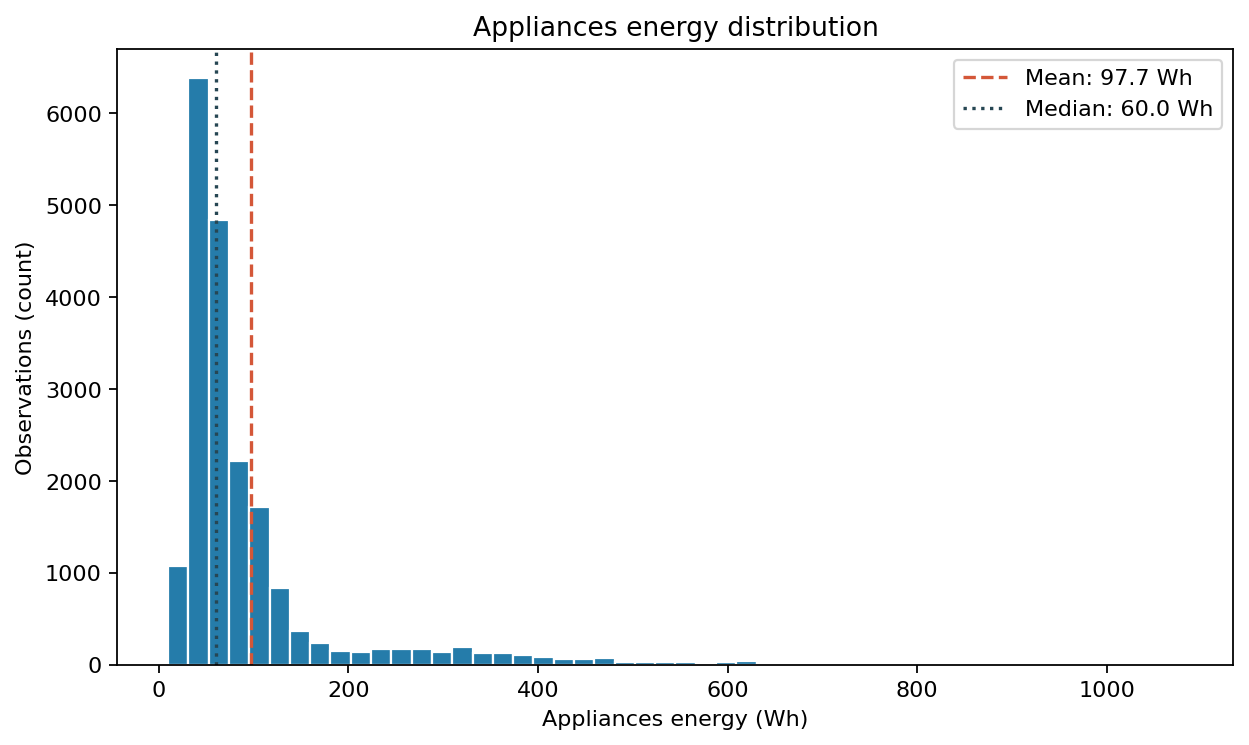

**02_appliances_boxplot.png**

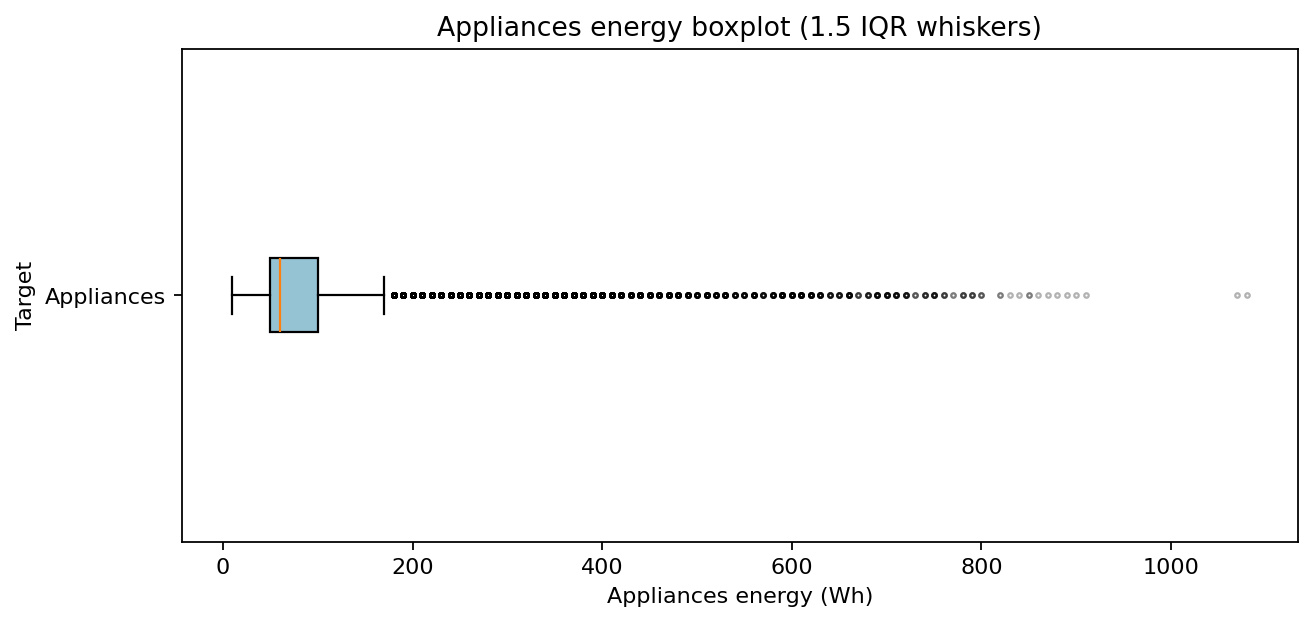

**03_appliances_time_series.png**

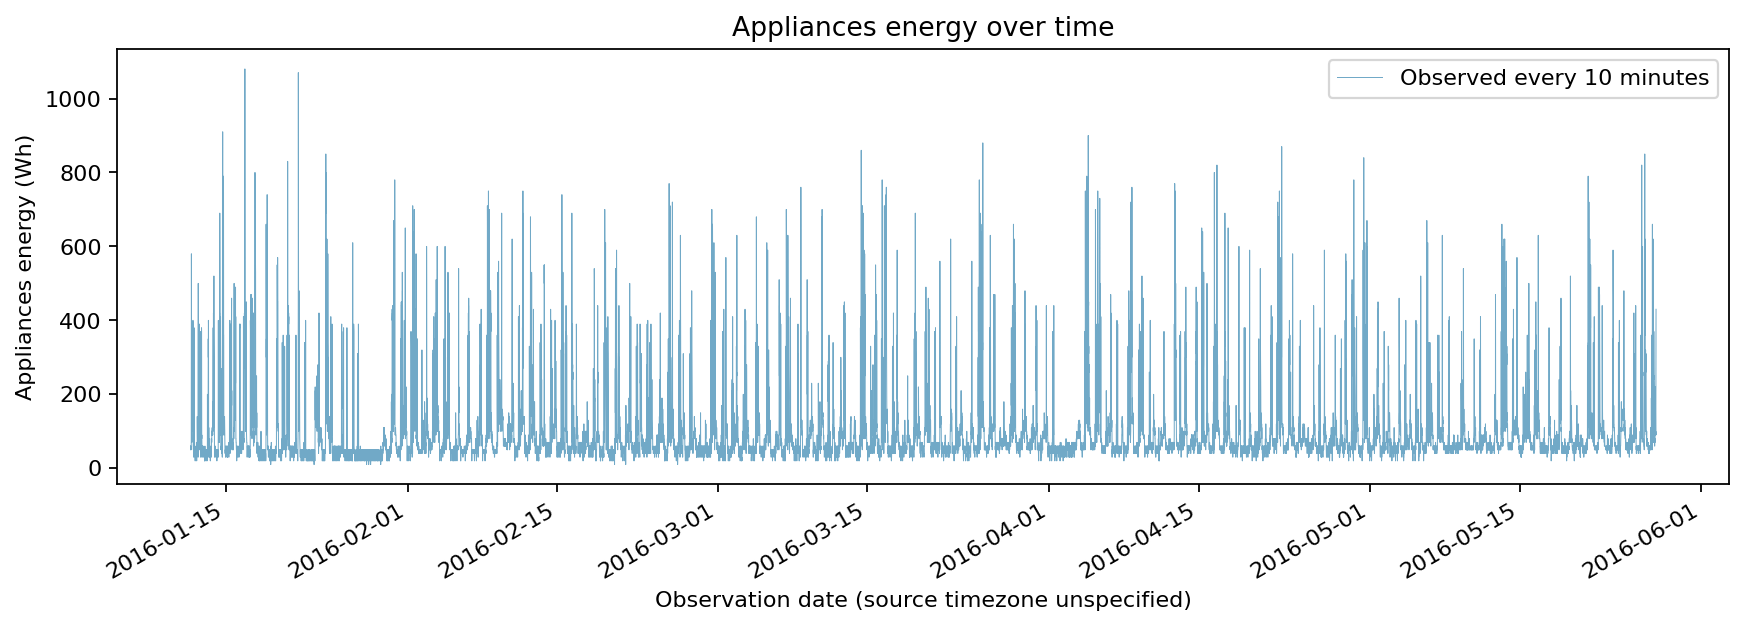

**04_numerical_correlation_heatmap.png**

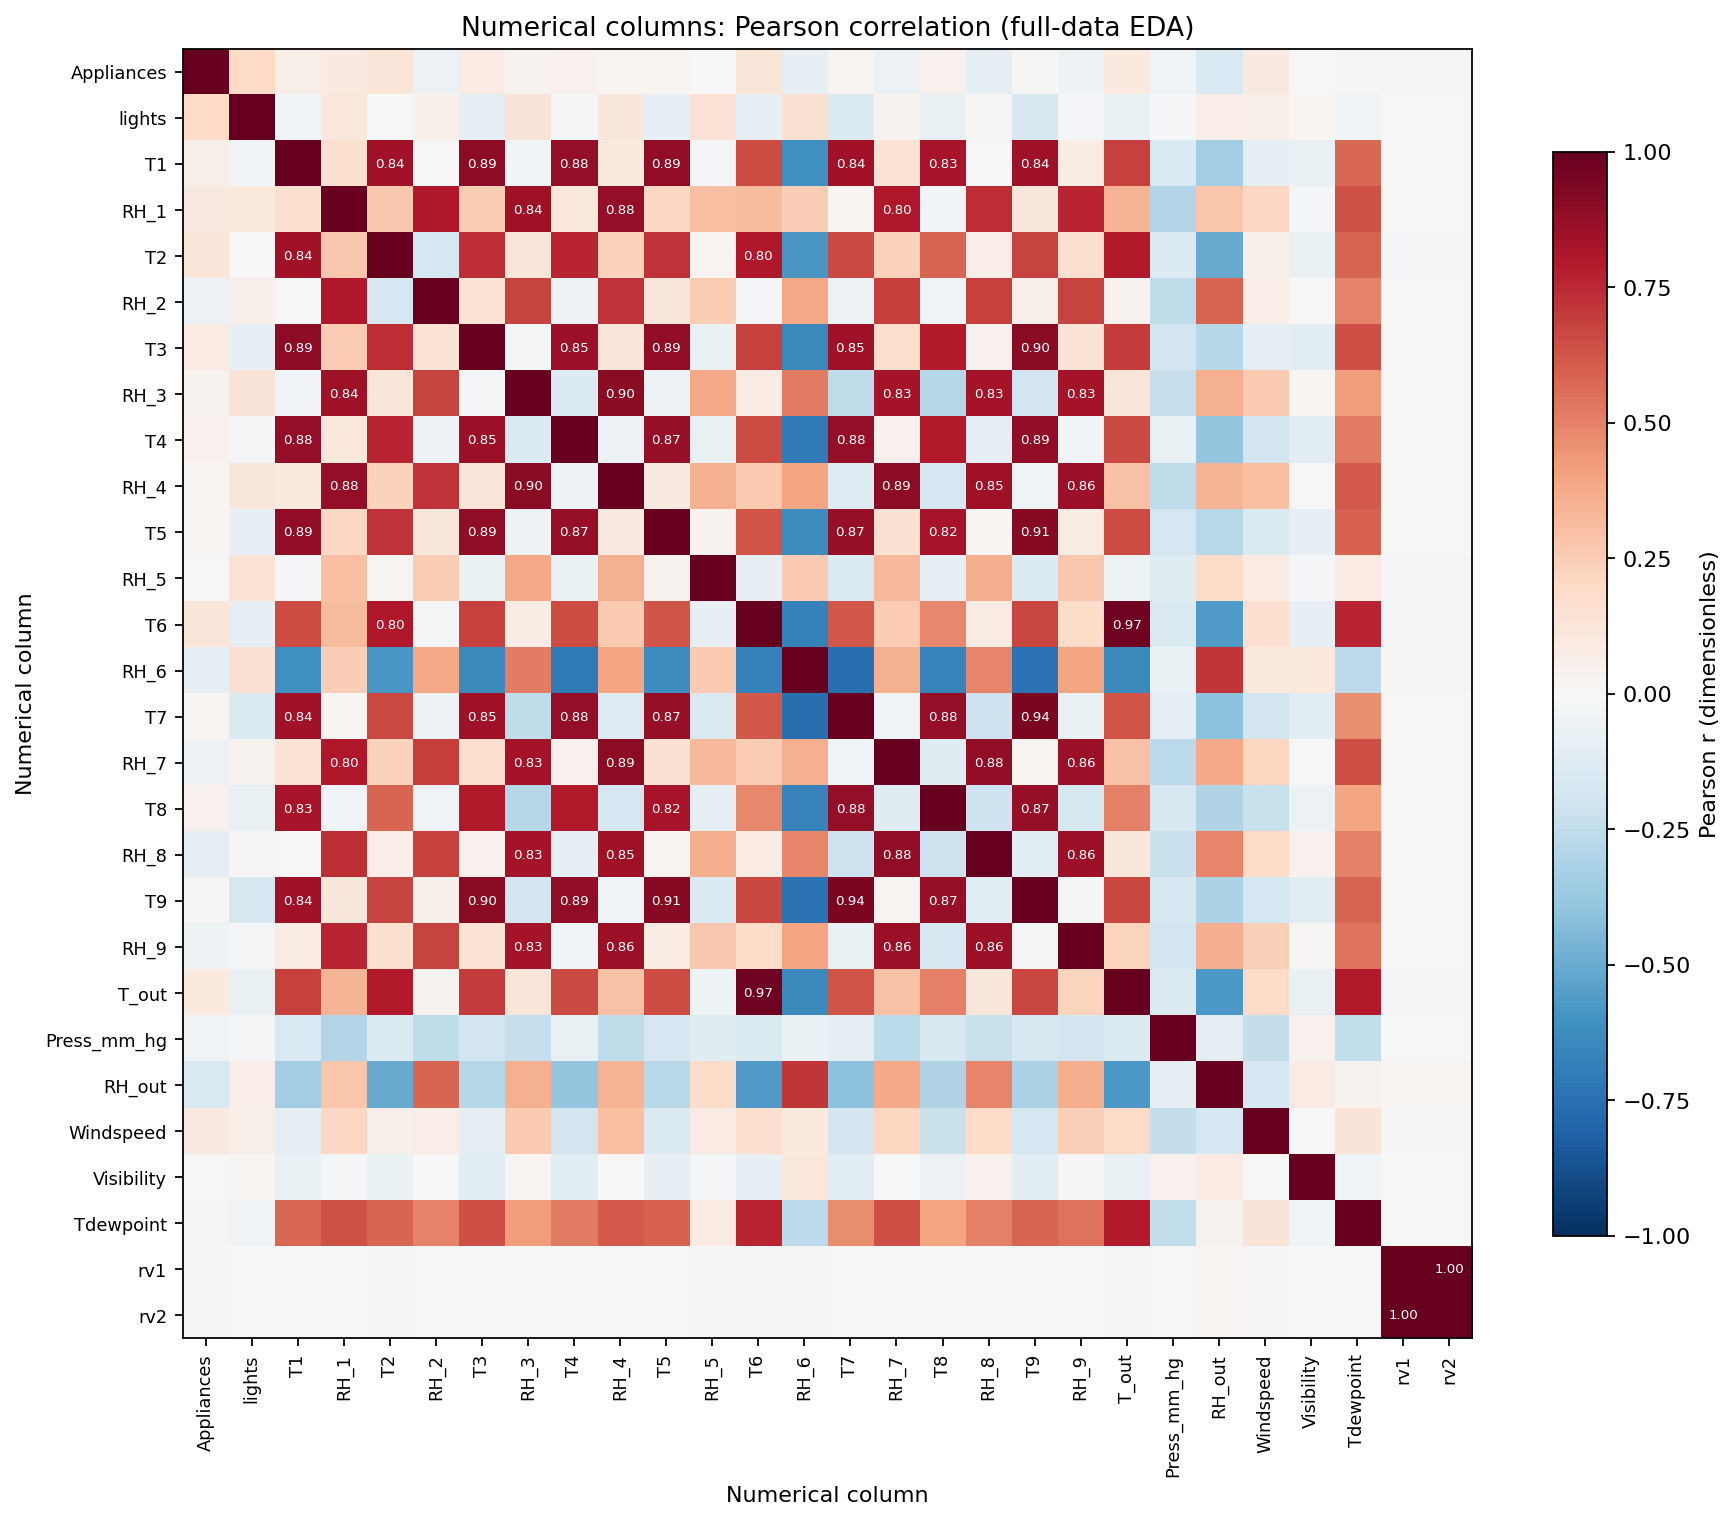

**05_feature_target_correlation_ranking.png**

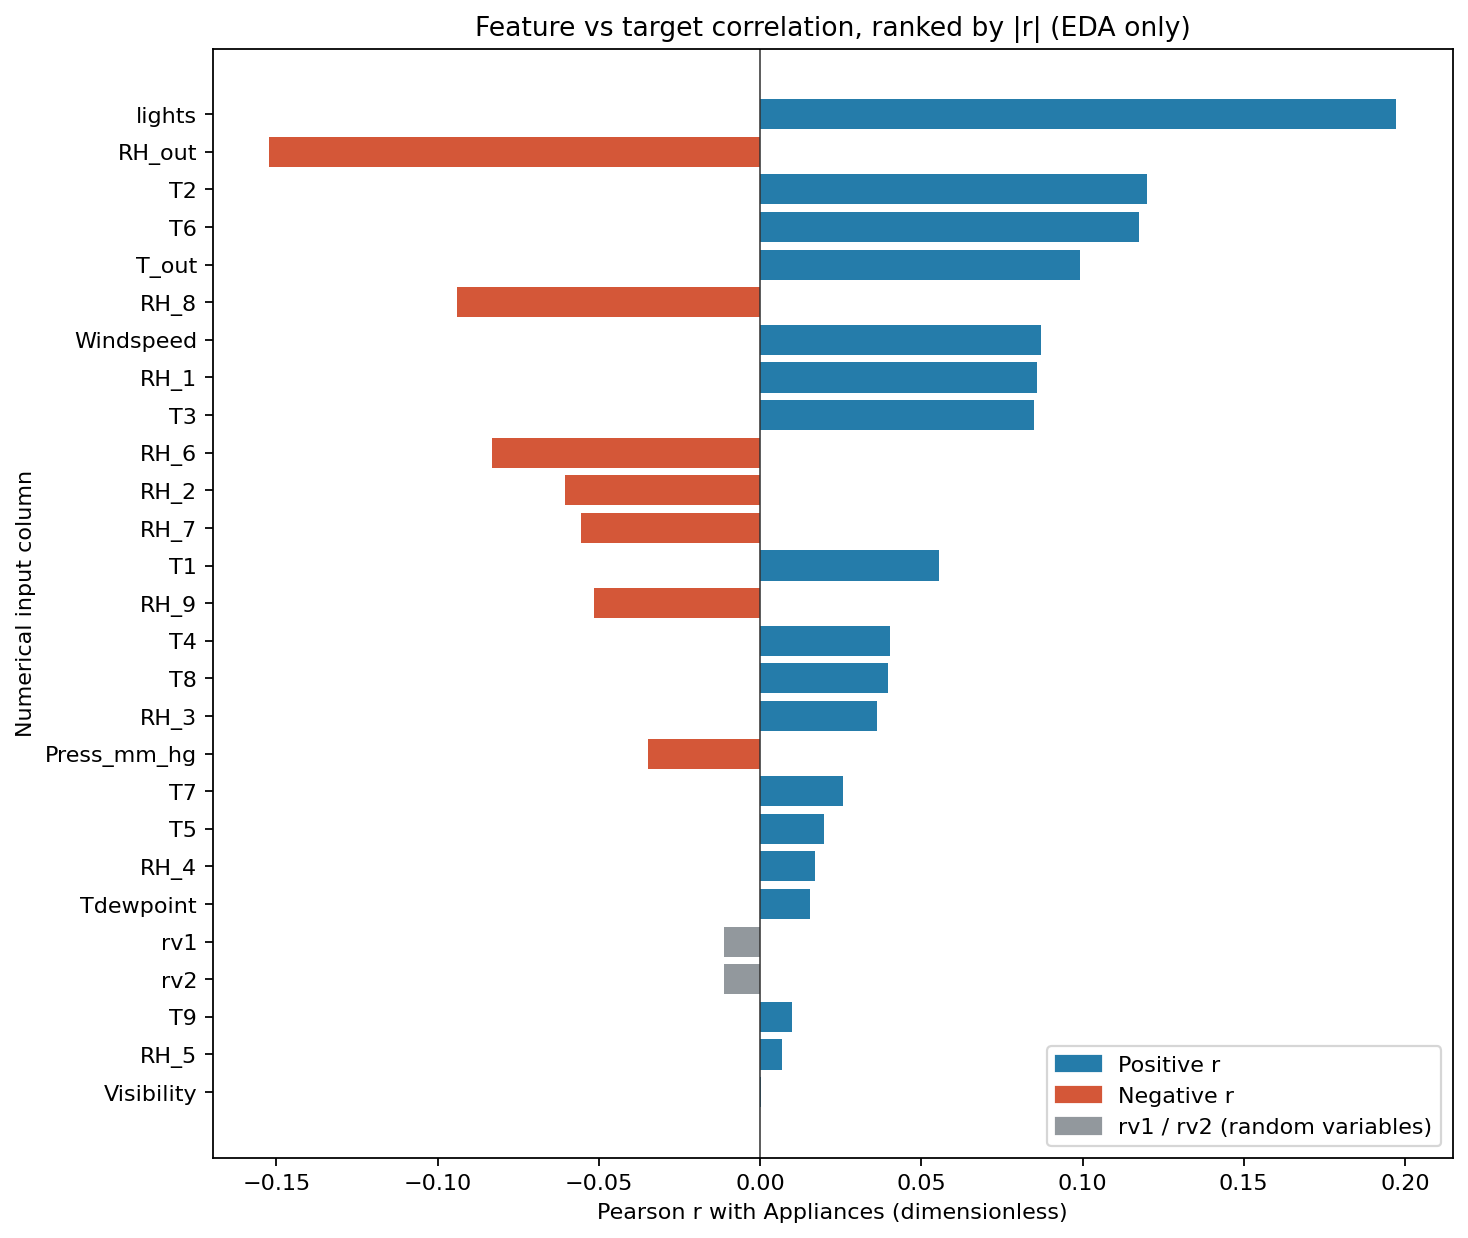

**06_hourly_appliances_pattern.png**

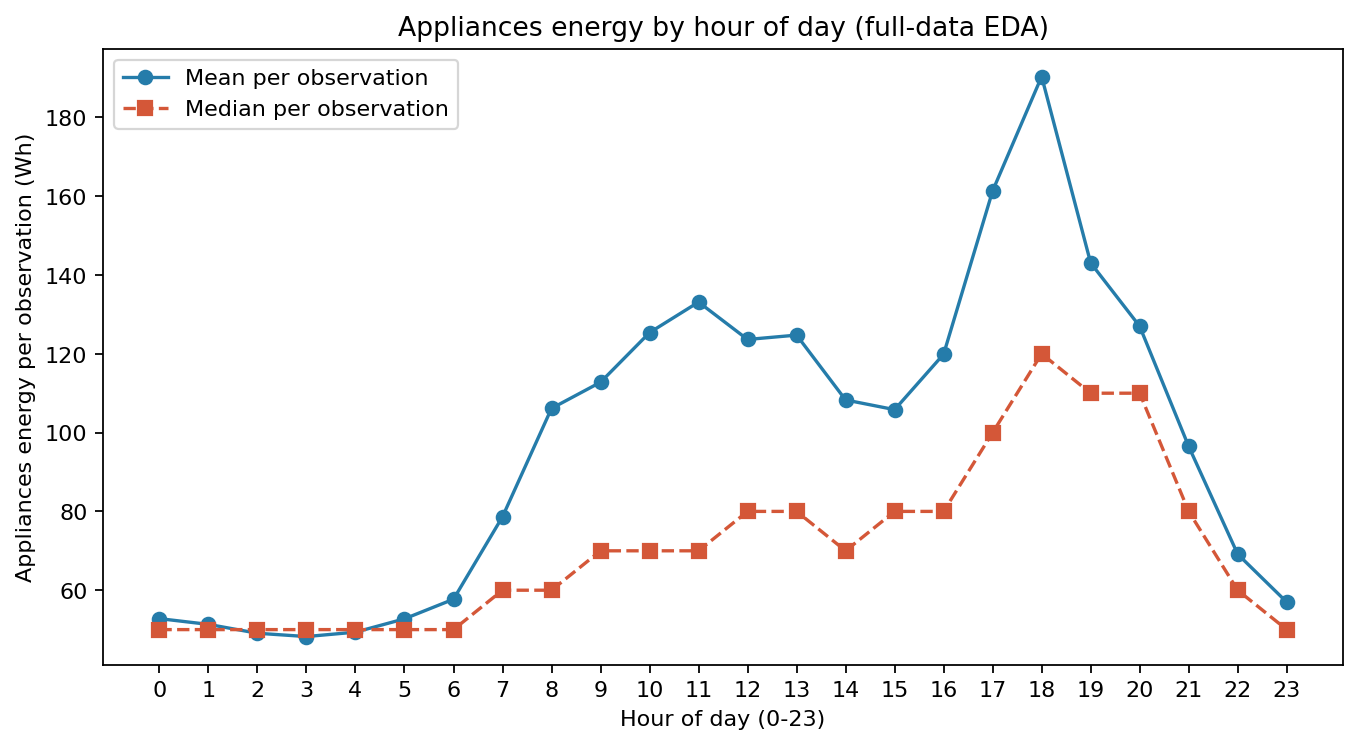

**07_weekday_appliances_pattern.png**

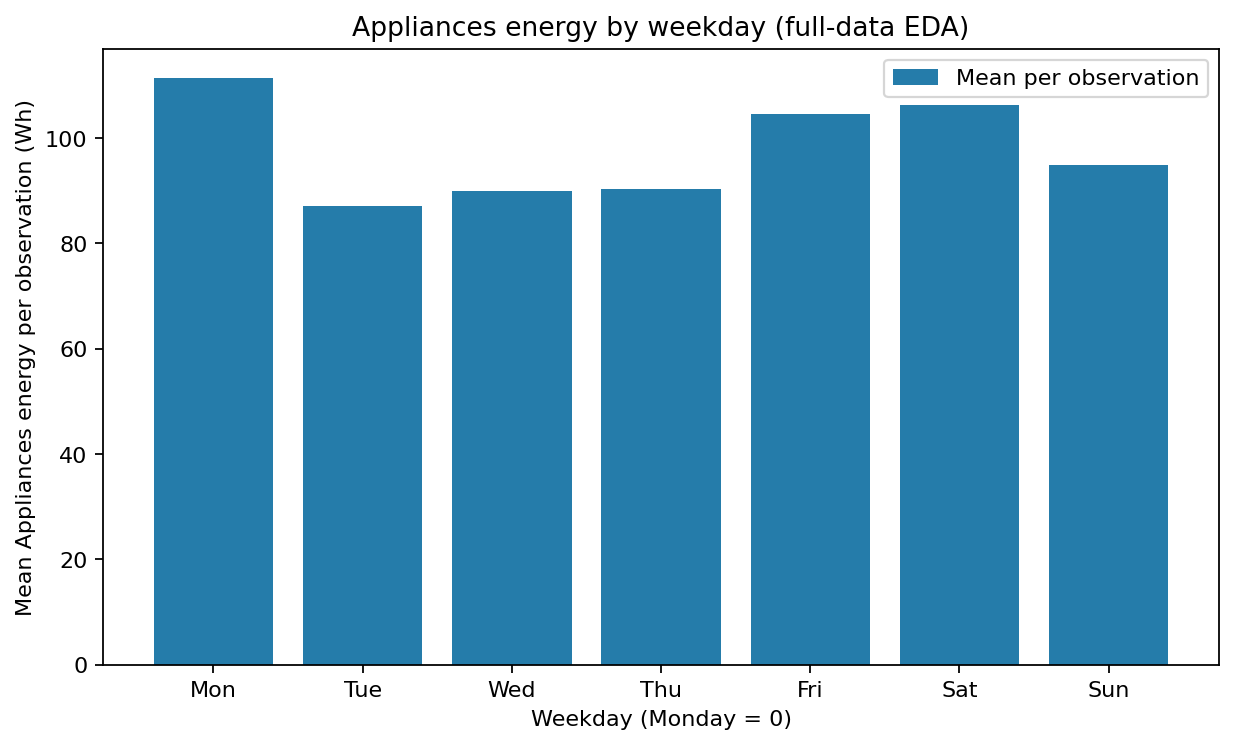

**15_numerical_distributions.png**

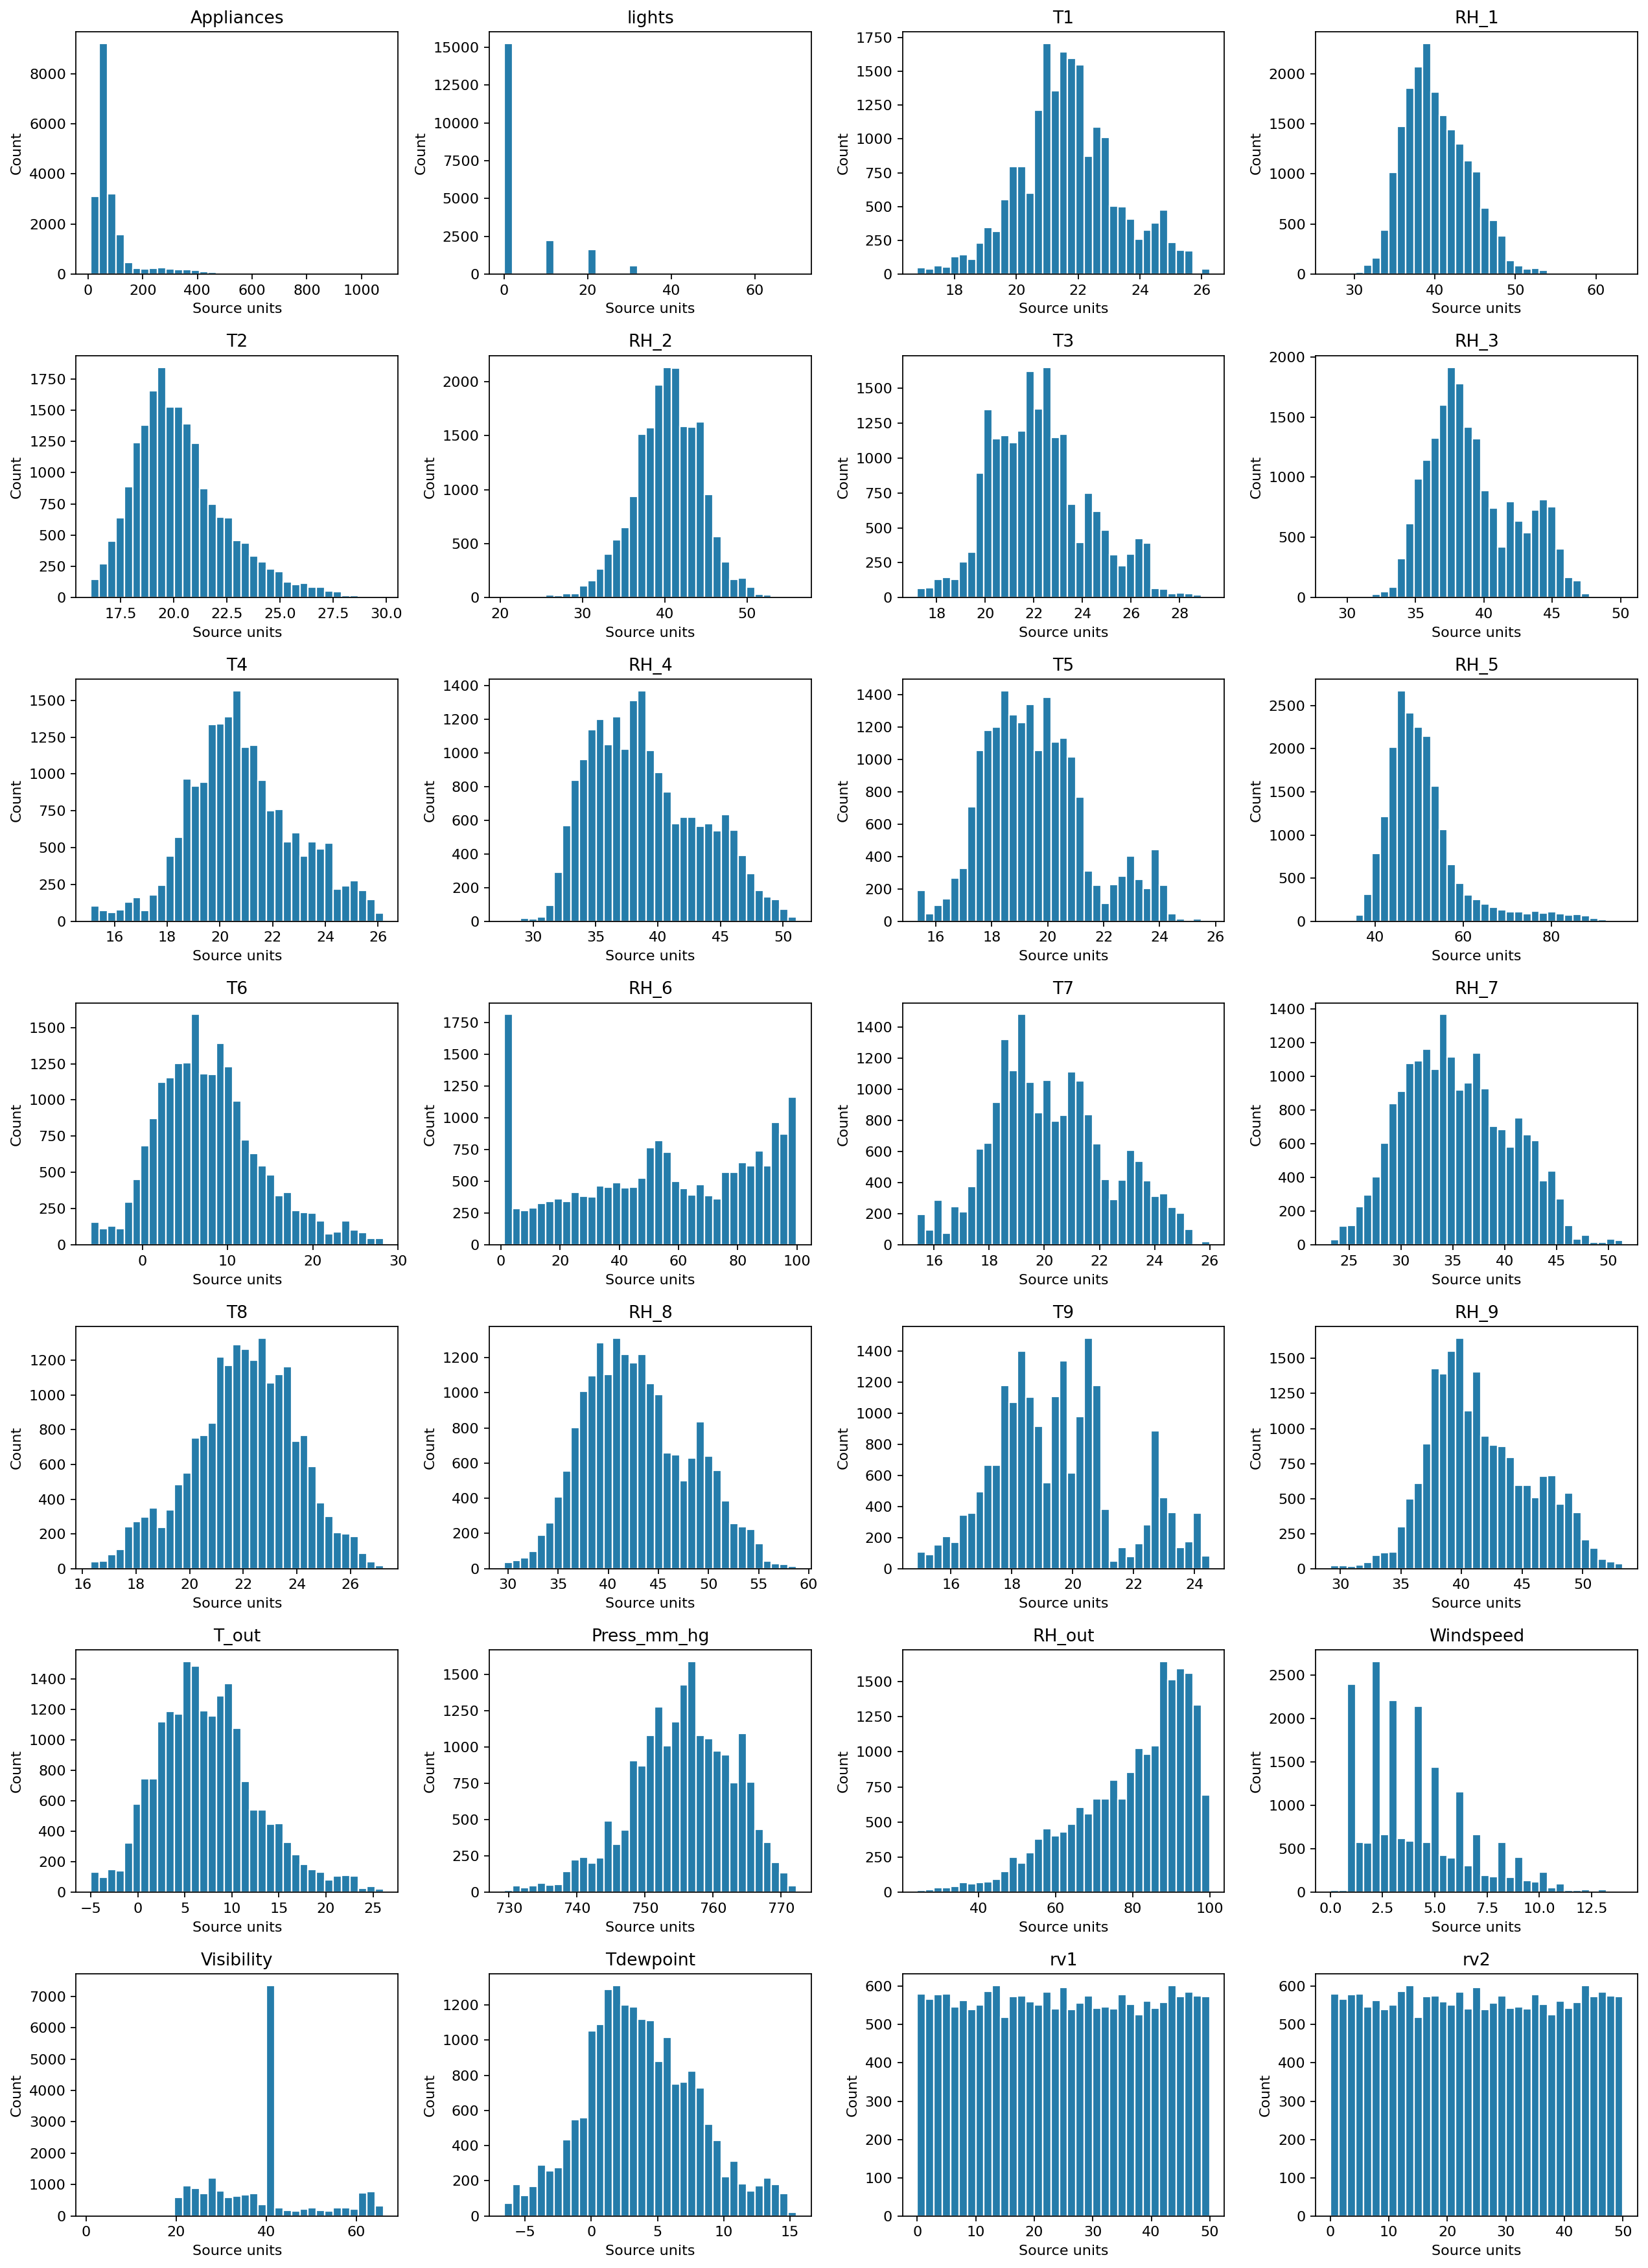

**16_monthly_and_autocorrelation.png**

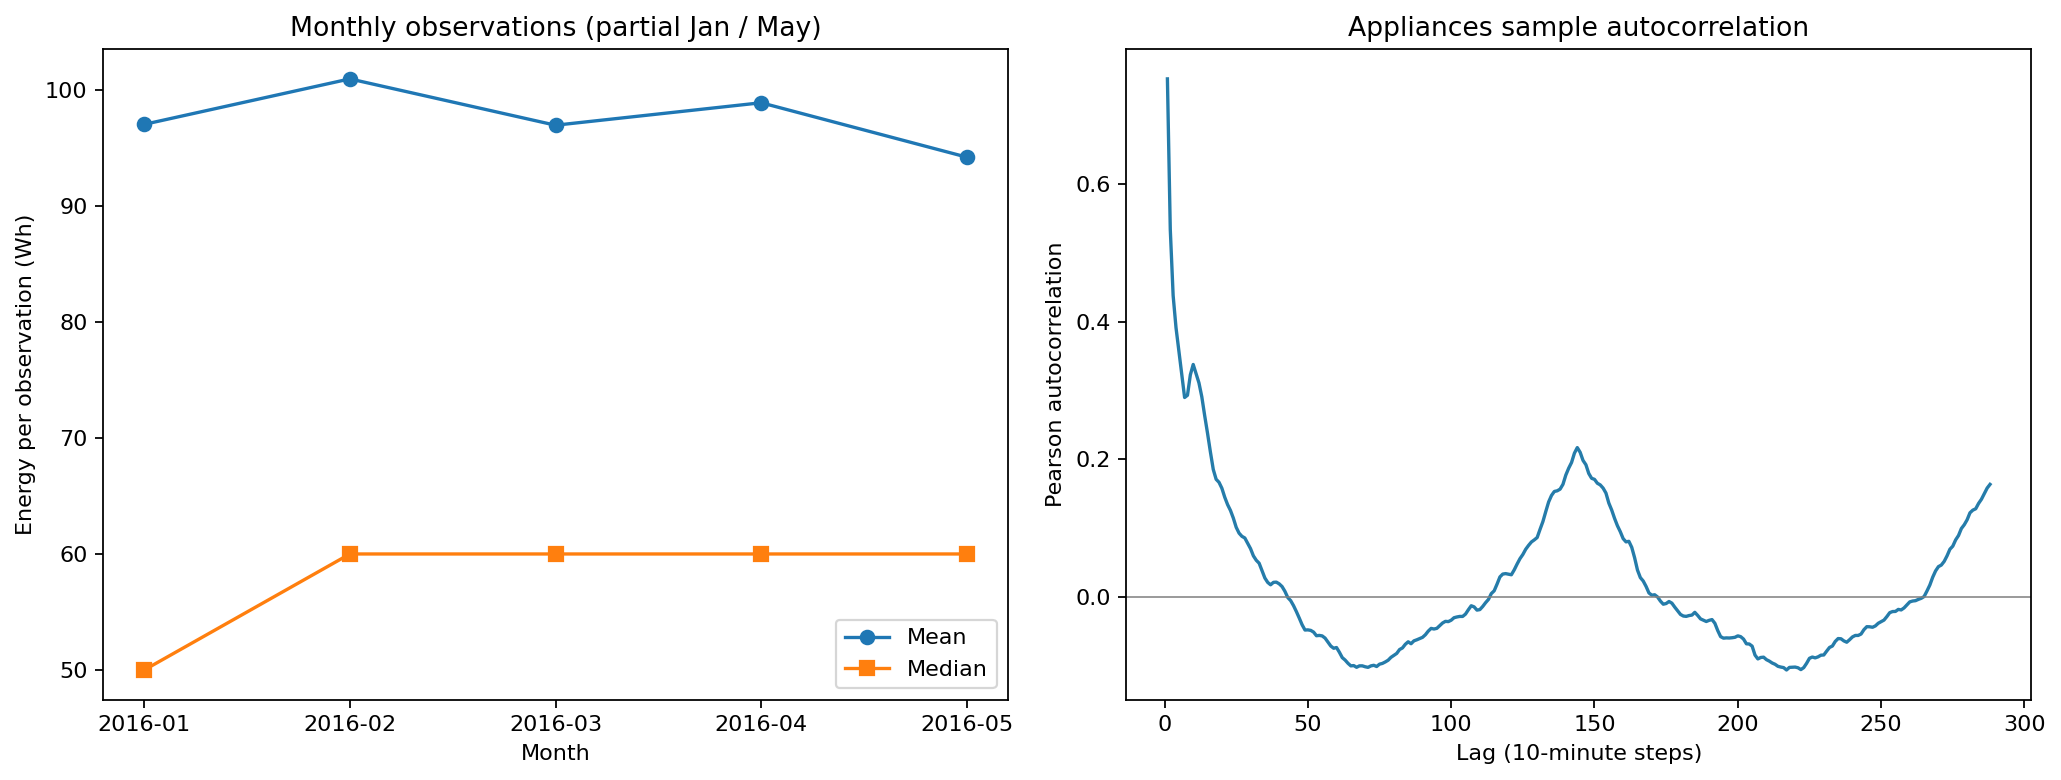

# Phase 2：Exploratory Data Analysis

本分析描述全部 19,735 筆資料；沒有依整份資料的 Target 相關係數進行正式 Feature Selection。未來 holdout 也包含在描述性 EDA 中，因此這些觀察不能作為調參或泛化能力證據。所有原始資料完整保留；本次沒有訓練或評估正式模型。

## Target 分布與異常值候選

`Appliances` 為能源讀值，單位 Wh。平均 97.695 Wh、中位數 60.000 Wh、樣本標準差 102.525 Wh，最小 10.000 Wh、最大 1080.000 Wh。偏態 3.386367、超額峰度 13.667863；平均高於中位數且右側長尾，少數高讀值可能對平方誤差造成較大影響。

以 1.5 × IQR 描述性規則標記：下界 -25.000 Wh、上界 175.000 Wh；下界外 0 筆、上界外 2138 筆，合計占 10.83%。這些是需要理解的高低值，不能直接認定為測量錯誤；未刪除、截尾或補值。

## 數值相關係數

Heatmap 包含 Target 與所有數值輸入欄位。下表依與 Target 的 Pearson |r| 排序，保留 r 的正負號；只描述線性關聯，不代表因果關係或選模結果。

| 欄位 | Pearson r 與 Appliances |
| --- | ---: |
| lights | 0.197278 |
| RH_out | -0.152282 |
| T2 | 0.120073 |
| T6 | 0.117638 |
| T_out | 0.099155 |
| RH_8 | -0.094039 |
| Windspeed | 0.087122 |
| RH_1 | 0.086031 |
| T3 | 0.085060 |
| RH_6 | -0.083178 |
| RH_2 | -0.060465 |
| RH_7 | -0.055642 |
| T1 | 0.055447 |
| RH_9 | -0.051462 |
| T4 | 0.040281 |
| T8 | 0.039572 |
| RH_3 | 0.036292 |
| Press_mm_hg | -0.034885 |
| T7 | 0.025801 |
| T5 | 0.019760 |
| RH_4 | 0.016965 |
| Tdewpoint | 0.015353 |
| rv1 | -0.011145 |
| rv2 | -0.011145 |
| T9 | 0.010010 |
| RH_5 | 0.006955 |
| Visibility | 0.000230 |

輸入欄位間 |r| ≥ 0.8 的配對共 36 組，可能使迴歸係數不穩定，不能把單一係數解讀成因果效果。

| 特徵 1 | 特徵 2 | Pearson r |
| --- | --- | ---: |
| rv1 | rv2 | 1.000000 |
| T6 | T_out | 0.974787 |
| T7 | T9 | 0.944776 |
| T5 | T9 | 0.911055 |
| T3 | T9 | 0.901324 |
| RH_3 | RH_4 | 0.898978 |
| RH_4 | RH_7 | 0.894301 |
| T1 | T3 | 0.892402 |
| T4 | T9 | 0.889439 |
| T3 | T5 | 0.888169 |
| T1 | T5 | 0.885247 |
| RH_7 | RH_8 | 0.883984 |
| T7 | T8 | 0.882123 |
| RH_1 | RH_4 | 0.880359 |
| T4 | T7 | 0.877763 |
| T1 | T4 | 0.877001 |
| T4 | T5 | 0.871813 |
| T5 | T7 | 0.870624 |
| T8 | T9 | 0.869338 |
| RH_7 | RH_9 | 0.858686 |
| RH_4 | RH_9 | 0.856591 |
| RH_8 | RH_9 | 0.855812 |
| T3 | T4 | 0.852778 |
| T3 | T7 | 0.847374 |
| RH_4 | RH_8 | 0.847259 |
| T1 | T9 | 0.844777 |
| RH_1 | RH_3 | 0.844677 |
| T1 | T7 | 0.838705 |
| T1 | T2 | 0.836834 |
| RH_3 | RH_9 | 0.833538 |
| RH_3 | RH_7 | 0.832685 |
| RH_3 | RH_8 | 0.828822 |
| T1 | T8 | 0.825413 |
| T5 | T8 | 0.824981 |
| T2 | T6 | 0.801186 |
| RH_1 | RH_7 | 0.801122 |

`rv1`、`rv2` 的全部值完全相同；[UCI 原始欄位定義](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction) 說明它們是加入資料供回歸與非預測屬性檢查的隨機變數。可作負對照，但不能假設有限樣本相關性恰為零。建議可覆寫地排除兩欄，避免重複欄位與無物理意義的輸入；不是演算法優劣結論。

標準化的 27 個數值輸入矩陣秩為 26，condition number 為 5.463e+15。此診斷未計算 VIF；秩不足與高度相關可能導致係數不唯一或不穩定。LinearRegression 可用最小平方求解，但單一係數解讀需保守。

## 各欄分布與資料品質

各欄型態、缺失值、唯一值數量，以及 28 個數值欄位的 count、mean、std、min、四分位數、max、skewness、IQR 候選數都存於 `eda_statistics.json`。原始 CSV 的 `date` 為字串，此處只在記憶體解析成 datetime。逐欄直方圖見第 15 張圖；不同量綱與偏態支持將縮放設為可設定選項，沒有預先修改原始值。

## 時間與消耗模式

全資料按小時分組後，平均每筆讀值最高為 18:00（190.365 Wh），最低為 03:00（48.236 Wh）。按星期分組後，最高為 星期一（111.451 Wh），最低為 星期二（87.125 Wh）。分組的 mean、median、std 與樣本數保存在 `eda_statistics.json`。

小時與星期圖表示**該時段觀測值的平均／中位數**，不是每小時或每日總耗能，也不是功率 W。未進行時區推定或季節調整。資料只有一棟住宅約 4.5 個月，時段差異可能同時受到作息、天氣與季節影響；不能推定因果或一般住宅的節能效果。

月份 count／mean／median／std 及 Target、T1、T_out、RH_1 在 10 分鐘、1 小時、1 天、1 週的自相關列於 JSON；1 月與 5 月不完整，不宜直接解讀成完整月份總耗能。Target lag-1 自相關為 0.753166，顯示相鄰觀測非獨立。建議 chronological holdout，加上訓練區內 TimeSeriesSplit；gap 為待按預測視窗決定的設定，不由 holdout 分數選取。天氣資料的插值與感測器平滑也可能加強鄰近依賴。

## 圖表

- [01_appliances_histogram.png](figures/01_appliances_histogram.png)
- [02_appliances_boxplot.png](figures/02_appliances_boxplot.png)
- [03_appliances_time_series.png](figures/03_appliances_time_series.png)
- [04_numerical_correlation_heatmap.png](figures/04_numerical_correlation_heatmap.png)
- [05_feature_target_correlation_ranking.png](figures/05_feature_target_correlation_ranking.png)
- [06_hourly_appliances_pattern.png](figures/06_hourly_appliances_pattern.png)
- [07_weekday_appliances_pattern.png](figures/07_weekday_appliances_pattern.png)
- [15_numerical_distributions.png](figures/15_numerical_distributions.png)
- [16_monthly_and_autocorrelation.png](figures/16_monthly_and_autocorrelation.png)


In [5]:
eda = run_eda(frame)
assert len(eda["figures"]) == 9
assert len(set(eda["figures"])) == 9
for figure in eda["figures"]:
    display(Markdown(f"**{Path(figure).name}**"))
    display(Image(filename=str(ROOT / figure)))
display(Markdown((ROOT / "reports/phase2/eda_summary.md").read_text(encoding="utf-8")))

## 5. Feature Preparation

既有 Baseline 依 `src.phase2_common.prepare_features` 排除 Target、date、rv1、rv2，固定保留 25 個數值欄位。date 只供該 Baseline 的切分與分析；rv1／rv2 隨機且相同。這兩個 Baseline 沒有衍生時間特徵、scaler、補值器或正式 Feature Selection。

後段的可設定前處理示例屬獨立核心驗收，支援 StandardScaler 與 calendar，並不改變既有 Baseline 的設定或分數。

In [6]:
X, y = prepare_features(frame)
assert X.shape[1] == 25
assert not {"Appliances", "date", "rv1", "rv2"}.intersection(X.columns)
print("Baseline Feature Count：", X.shape[1])
display(pd.DataFrame({"Feature": X.columns}))

Baseline Feature Count： 25


,Feature
0,lights
1,T1
2,RH_1
3,T2
4,RH_2
5,T3
6,RH_3
7,T4
8,RH_4
9,T5


## 6. Chronological Split

主要設計為原始順序前 80% Training、後 20% Testing，不 Shuffle。Testing 的時間必須晚於 Training。完整切分與日期範圍由 `src.train_baseline` 統一建立。

In [7]:
splits = create_splits(frame)
chrono_train, chrono_test = splits["chronological"]
assert frame.loc[chrono_train, "date"].max() < frame.loc[chrono_test, "date"].min()
print("Chronological Training：", len(chrono_train), "Testing：", len(chrono_test))
print("Training 日期：", frame.loc[chrono_train, "date"].min(), "至", frame.loc[chrono_train, "date"].max())
print("Testing 日期：", frame.loc[chrono_test, "date"].min(), "至", frame.loc[chrono_test, "date"].max())

Chronological Training： 15788 Testing： 3947
Training 日期： 2016-01-11 17:00:00 至 2016-04-30 08:10:00
Testing 日期： 2016-04-30 08:20:00 至 2016-05-27 18:00:00


## 7. Baseline Linear Regression

呼叫 `src.train_baseline.load_verified_baselines(frame)`，載入兩個既有 `LinearRegression()` 模型，沿用共用切分與指標函式，在記憶體核對 Training／Testing 預測指標。此函式不 fit、不儲存模型、不改寫 Baseline Metrics，也不做測試集調參或選模。

模型、特徵順序、係數與 training metadata 已存在 `reports/phase2/models/`。原先會重新訓練並寫入模型的 `run_baselines` 不再由此 Notebook 呼叫。

In [8]:
baseline = load_verified_baselines(frame)
chronological = baseline["baselines"]["chronological"]
display(pd.DataFrame({"Training": chronological["train_metrics"],
                      "Testing": chronological["test_metrics"]}))
print("主要模型：", chronological["model_file"])

,Training,Testing
mae,54.289188,52.014105
mse,9152.687409,7522.602624
rmse,95.669679,86.732939
r2,0.172899,0.092352


主要模型： reports/phase2/models/chronological_baseline.joblib


## 8. Random Split Comparison

使用相同的 25 欄與預設模型，隨機 80%／20%、random_state=42。相鄰時間可能分散在兩側，故只比較，不當成真正未來預測能力，也不依其分數選取最終模型。

In [9]:
random = baseline["baselines"]["random"]
assert random["split_metadata"]["random_state"] == 42
print("Random Training：", random["split_metadata"]["train"]["count"],
      "Testing：", random["split_metadata"]["test"]["count"])
display(pd.DataFrame({"Training": random["train_metrics"], "Testing": random["test_metrics"]}))
display(pd.DataFrame({"Chronological Testing": chronological["test_metrics"],
                      "Random Testing (comparison)": random["test_metrics"]}))

Random Training： 15788 Testing： 3947


,Training,Testing
mae,53.217383,52.547078
mse,8897.953796,8312.271344
rmse,94.328966,91.171659
r2,0.163445,0.169362


,Chronological Testing,Random Testing (comparison)
mae,52.014105,52.547078
mse,7522.602624,8312.271344
rmse,86.732939,91.171659
r2,0.092352,0.169362


## 9. Model Evaluation

MAE／RMSE 單位 Wh，MSE 單位 Wh²，R² 無單位。以下 7 張既有圖均使用相應 Baseline 結果；前三類圖只使用 Testing 預測，比較圖分開 Training／Testing：

| 檔案 | 說明 |
| --- | --- |
| 08_chronological_actual_vs_predicted.png | 時間切分 Testing：Actual vs Predicted 與理想預測線 |
| 09_chronological_residual_vs_predicted.png | 時間切分 Testing：Residual vs Predicted 與零殘差線 |
| 10_chronological_residual_distribution.png | 時間切分 Testing：殘差分布 |
| 11_random_actual_vs_predicted.png | 隨機切分 Testing：Actual vs Predicted 與理想預測線 |
| 12_random_residual_vs_predicted.png | 隨機切分 Testing：Residual vs Predicted 與零殘差線 |
| 13_random_residual_distribution.png | 隨機切分 Testing：殘差分布 |
| 14_split_performance_comparison.png | 兩種切分的 Training／Testing 指標比較 |

Residual = actual − predicted。保留負預測，不自行截斷；未產生 Confidence／Prediction Interval。兩種測試集不同，不能只比較其分數就宣稱哪種切分有較佳未來預測能力。

**08_chronological_actual_vs_predicted.png**

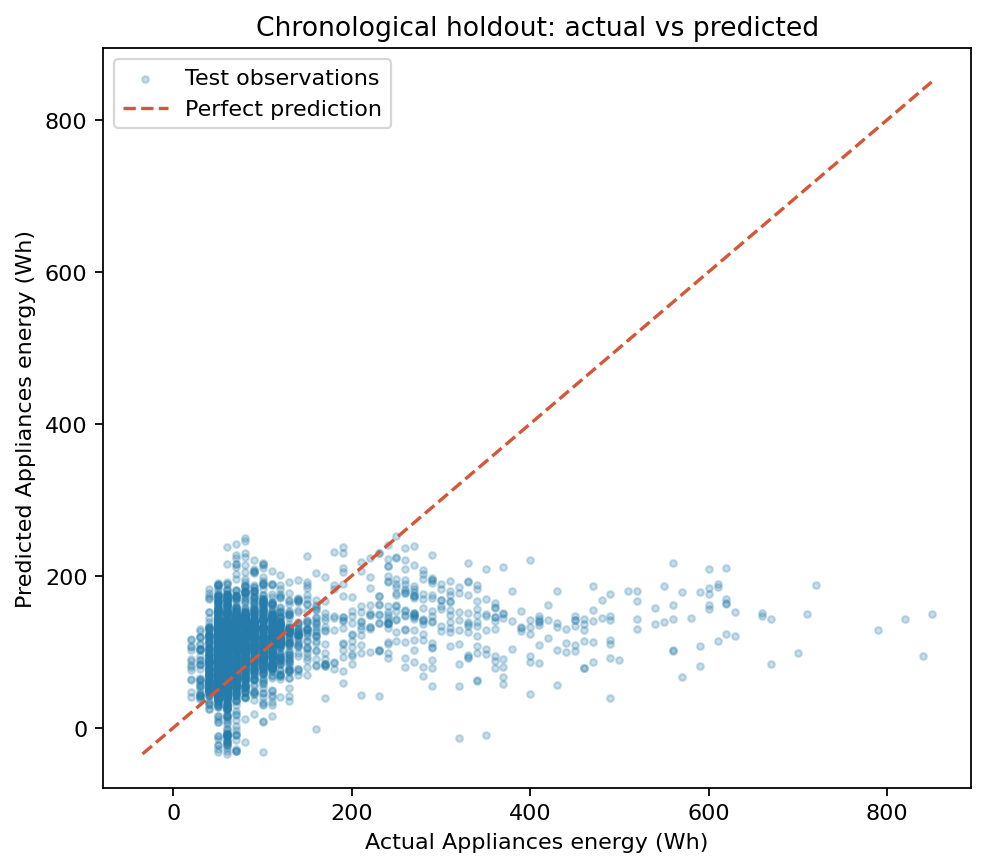

**09_chronological_residual_vs_predicted.png**

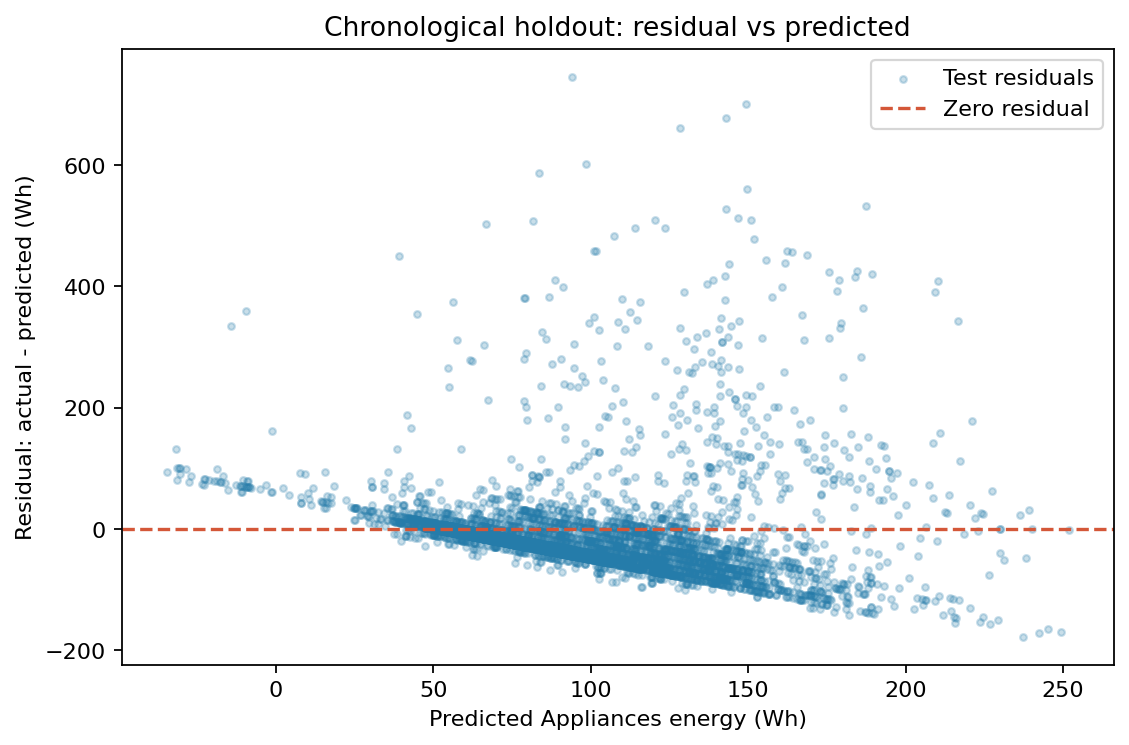

**10_chronological_residual_distribution.png**

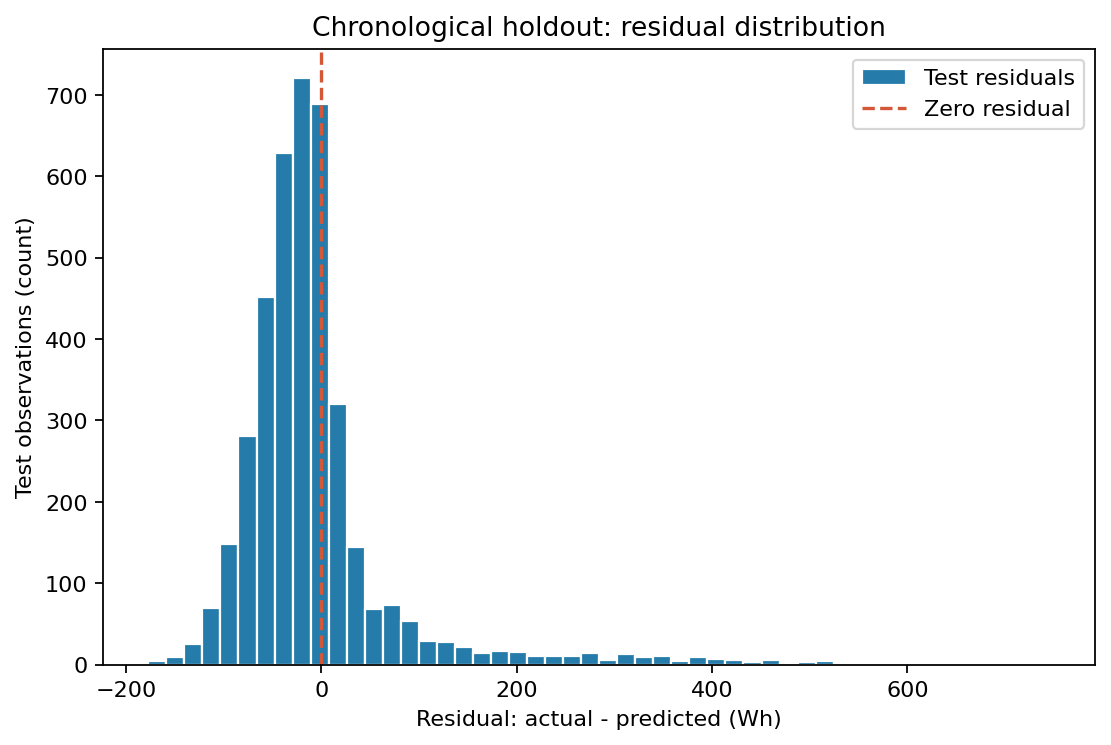

**11_random_actual_vs_predicted.png**

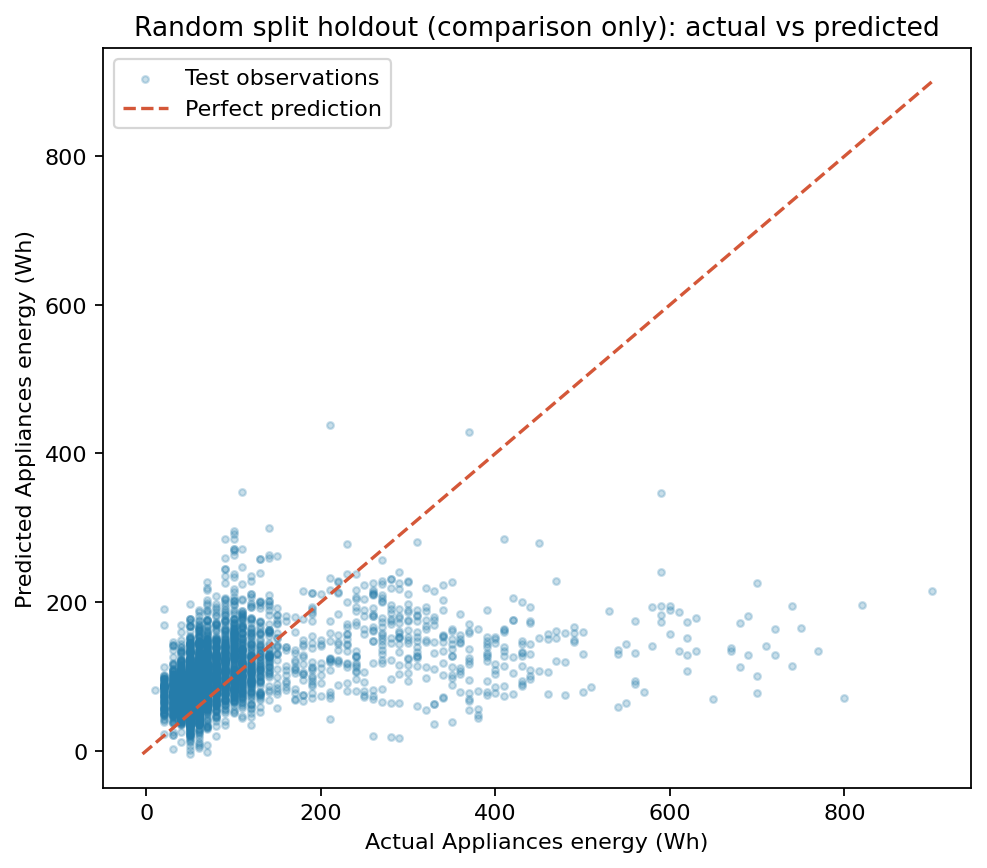

**12_random_residual_vs_predicted.png**

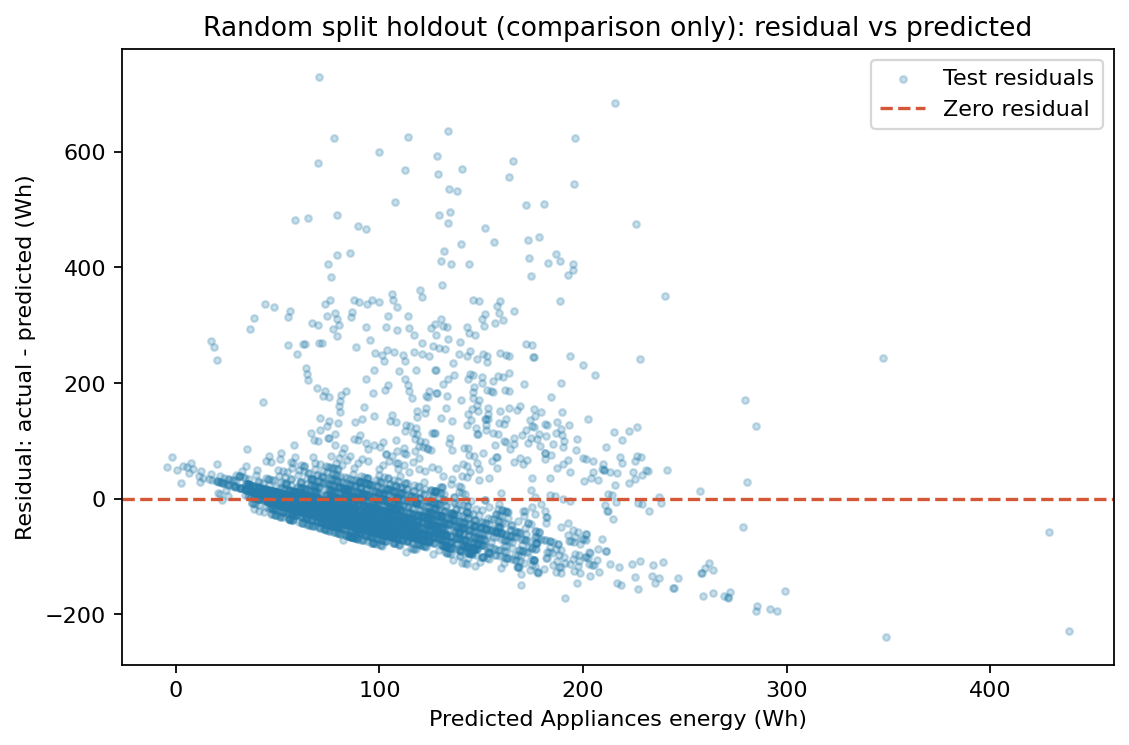

**13_random_residual_distribution.png**

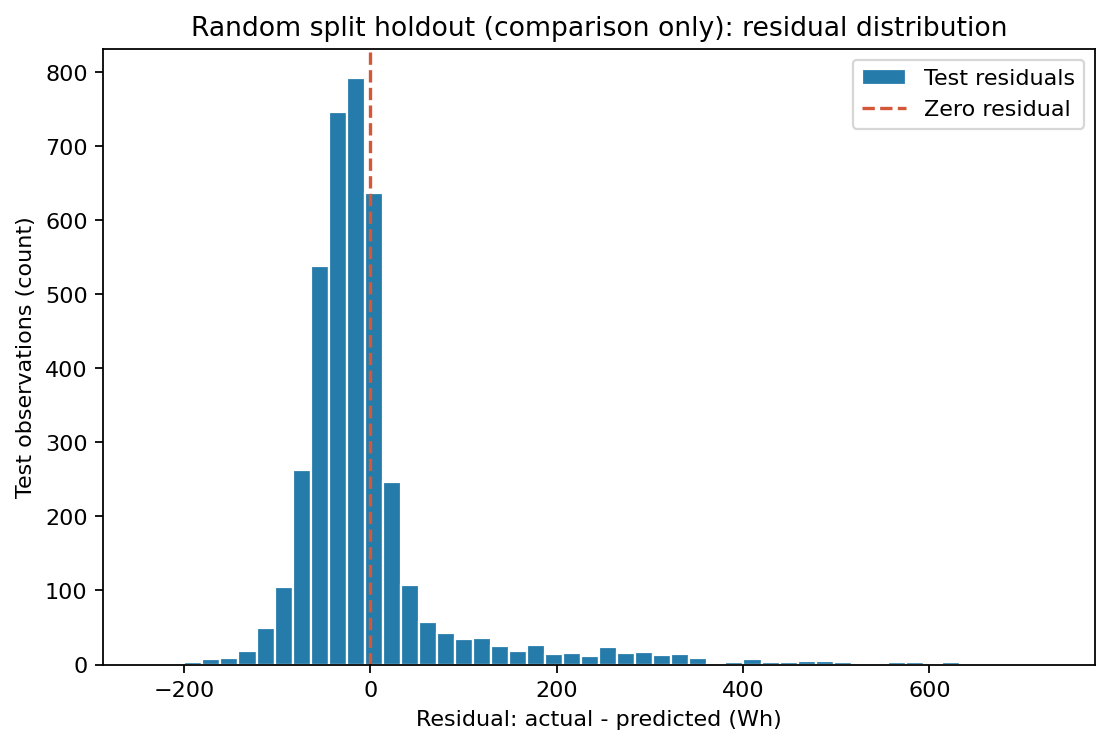

**14_split_performance_comparison.png**

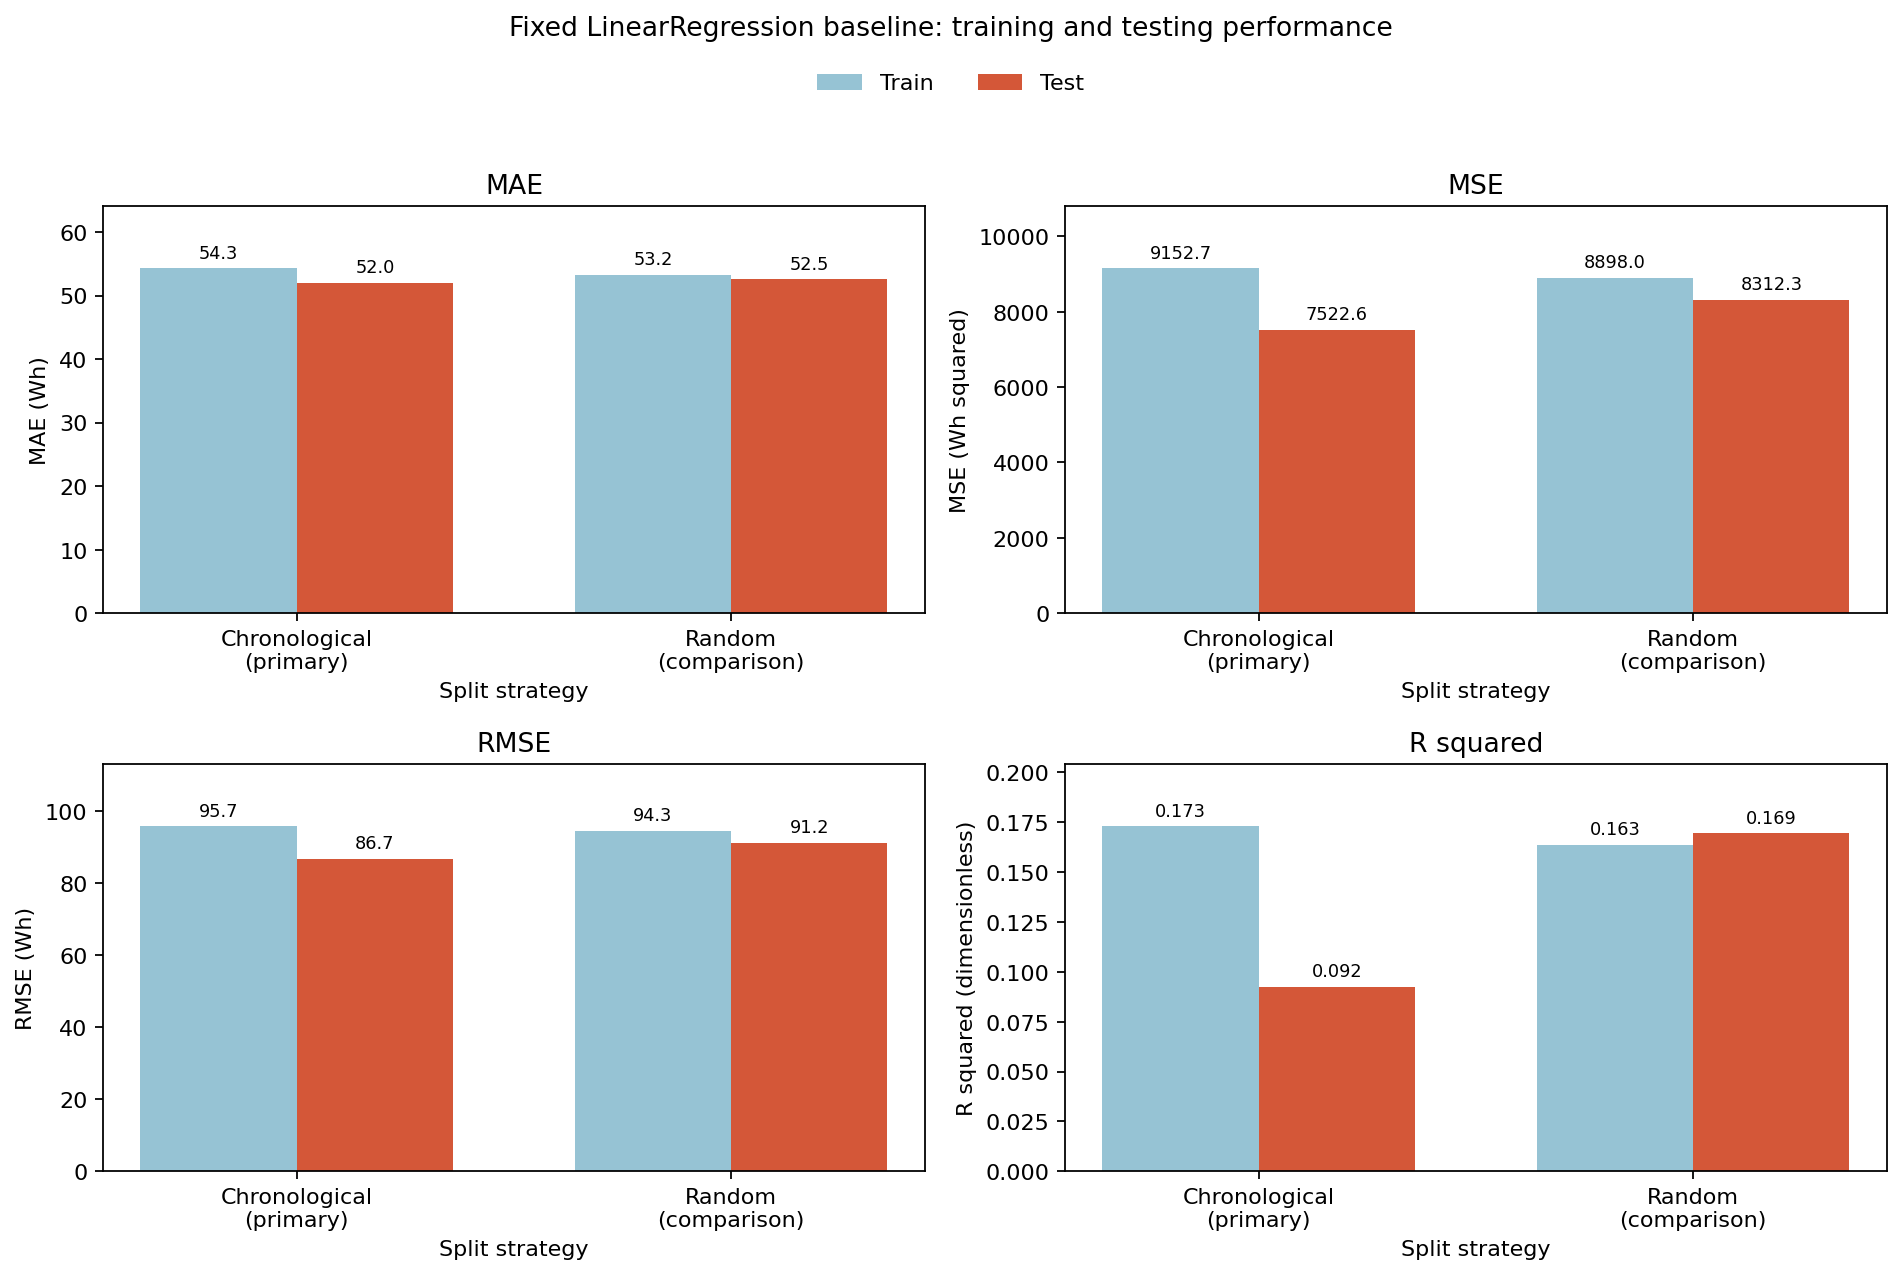

# Phase 2：Baseline Model Evaluation

## 設計與資料準備

兩個 Baseline 皆使用原樣的 `LinearRegression()`、相同的 25 個預先定義數值特徵：lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4, T5, RH_5, T6, RH_6, T7, RH_7, T8, RH_8, T9, RH_9, T_out, Press_mm_hg, RH_out, Windspeed, Visibility, Tdewpoint。

排除 Target `Appliances`、時間欄位 `date`、隨機且完全相同的 `rv1`／`rv2`。這是預先定義的 Baseline 資料品質處理，不是依 EDA 或模型分數進行 Feature Selection。`date` 保留供切分、樣本追溯與 EDA 使用，沒有衍生模型時間特徵。

**時間切分為主要結果**：原始順序前 80% Training、後 20% Testing，不 Shuffle。隨機切分使用 `train_test_split(test_size=0.2, random_state=42)`，僅供比較。沒有 scaler、缺失值補值器、參數調整、其他模型或依測試分數挑選最終模型。模型只在對應 Training fit；Training／Testing 指標分開計算。

| 切分 | Partition | 筆數 | 最早日期 | 最晚日期 |
| --- | --- | ---: | --- | --- |
| 時間切分（主要） | Training | 15788 | 2016-01-11T17:00:00 | 2016-04-30T08:10:00 |
| 時間切分（主要） | Testing | 3947 | 2016-04-30T08:20:00 | 2016-05-27T18:00:00 |
| 隨機切分（比較） | Training | 15788 | 2016-01-11T17:10:00 | 2016-05-27T18:00:00 |
| 隨機切分（比較） | Testing | 3947 | 2016-01-11T17:00:00 | 2016-05-27T17:50:00 |

完整資料列索引保存在 `split_indices.json`。JSON 記錄 date range、random_state、feature names、模型預設參數與環境版本；不儲存私人本機路徑。Random 的日期範圍重疊是方法本身的結果，不能解讀為未來外推能力。

## 指標與實測結果

MAE 為平均絕對誤差（Wh）；MSE 為平均平方誤差（Wh²）；RMSE 為 MSE 平方根（Wh），對較大的錯誤較敏感；R² 無單位，以上述 partition 的 Target 平均值作為分母基準，可能為負值。R² 不等於分類準確率或節能比例。

| 切分 | Partition | MAE（Wh） | MSE（Wh²） | RMSE（Wh） | R² |
| --- | --- | ---: | ---: | ---: | ---: |
| 時間切分（主要） | Training | 54.289188 | 9152.687409 | 95.669679 | 0.172899 |
| 時間切分（主要） | Testing | 52.014105 | 7522.602624 | 86.732939 | 0.092352 |
| 隨機切分（比較） | Training | 53.217383 | 8897.953796 | 94.328966 | 0.163445 |
| 隨機切分（比較） | Testing | 52.547078 | 8312.271344 | 91.171659 | 0.169362 |

- 時間切分（主要）：Testing − Training RMSE = -8.936740 Wh，R² 差 = -0.080547；測試集負預測 45 筆，殘差平均 -6.354935 Wh。
- 隨機切分（比較）：Testing − Training RMSE = -3.157307 Wh，R² 差 = 0.005917；測試集負預測 2 筆，殘差平均 -2.571514 Wh。

Training 與 Testing 是不同的觀測樣本；差距可觀察擬合與時間分布變化，不能單靠差距證明過擬合。Random 分數受到同一住宅、相鄰時間樣本可能同時落入兩側的影響，不能當成真正的未來預測能力。沒有根據兩個測試集分數反覆調整設定。

時間切分 Training 的 Target 平均／樣本標準差為 98.024449／105.198291 Wh，Testing 為 96.376995／91.050065 Wh。兩個期間的 Target 分布與變異不同，R² 的分母也不同；較低 RMSE 不必然代表較高 R²，不能用不同測試集的分數直接宣稱哪一種切分具有較佳未來預測能力。

## 係數與模型保存

時間切分 Intercept = -67.294852 Wh；隨機切分 Intercept = 23.193744 Wh。係數對應未標準化的原始欄位尺度，不能直接比較絕對值來做特徵重要性排名，也不能宣稱因果效果。

| Feature | 時間切分係數 | 隨機切分係數 |
| --- | ---: | ---: |
| lights | 2.139424 | 1.930226 |
| T1 | -6.374035 | 0.073979 |
| RH_1 | 12.854339 | 15.905544 |
| T2 | -13.205355 | -17.595725 |
| RH_2 | -12.410981 | -13.618769 |
| T3 | 27.709276 | 25.870400 |
| RH_3 | 8.634363 | 4.484464 |
| T4 | -3.795283 | -3.878785 |
| RH_4 | -2.445068 | -0.407502 |
| T5 | -1.675221 | -0.867705 |
| RH_5 | 0.105714 | 0.212372 |
| T6 | 7.636710 | 7.386886 |
| RH_6 | 0.341985 | 0.341426 |
| T7 | 1.075958 | 2.241512 |
| RH_7 | -0.489215 | -1.662980 |
| T8 | 9.038519 | 7.449571 |
| RH_8 | -5.960234 | -4.560437 |
| T9 | -14.350566 | -15.165642 |
| RH_9 | -0.998667 | -1.030043 |
| T_out | -8.626430 | -10.501871 |
| Press_mm_hg | 0.223381 | 0.162218 |
| RH_out | -0.520918 | -1.072619 |
| Windspeed | 1.273456 | 1.777901 |
| Visibility | 0.189684 | 0.161676 |
| Tdewpoint | 3.699699 | 5.007594 |

`models/chronological_baseline.joblib`、`models/random_baseline.joblib` 儲存模型及 feature names、intercept、coefficients、sklearn version、training metadata；對應的 `.json` 提供可讀資料。重新載入模型後，可用相同欄位順序預測；joblib 檔案僅供本專案可信來源使用。

測試集逐筆 actual、predicted、residual 與原始 row index／date 保存於 `predictions_chronological.csv`、`predictions_random.csv`。三類評估圖均只使用該模型的 Testing 預測，沒有混入 Training 資料。比較圖明確分開 Training／Testing。

## 發現與限制

Baseline 可能低估極端耗能尖峰；請同時觀察 Actual vs Predicted、殘差分布與殘差隨預測值的型態。所有預測保留 LinearRegression 原始輸出，包括負值，未截斷或依測試集修正。OLS 的線性、加成形式可能無法描述作息、尖峰與非線性關係，輸入間高度相關也可能使係數不穩定。

此流程以**同一時間的感測器與天氣資訊估計當下 Appliances**，不是只靠歷史資料預測未來時點的多步模型；時間 Holdout 僅模擬未見過的後期資料。實際使用仍須確認這些輸入在預測時是否可取得。資料涵蓋單棟住宅約 4.5 個月，測試期間只有後 20%，沒有跨年度、跨住宅或外部驗證；未執行交叉驗證。未建立 Confidence Interval／Prediction Interval，未開始 Phase 3–4。

## 圖表

- [08_chronological_actual_vs_predicted.png](figures/08_chronological_actual_vs_predicted.png)
- [09_chronological_residual_vs_predicted.png](figures/09_chronological_residual_vs_predicted.png)
- [10_chronological_residual_distribution.png](figures/10_chronological_residual_distribution.png)
- [11_random_actual_vs_predicted.png](figures/11_random_actual_vs_predicted.png)
- [12_random_residual_vs_predicted.png](figures/12_random_residual_vs_predicted.png)
- [13_random_residual_distribution.png](figures/13_random_residual_distribution.png)
- [14_split_performance_comparison.png](figures/14_split_performance_comparison.png)


In [10]:
assert len(baseline["figures"]) == 7
assert len(set(baseline["figures"])) == 7
for name, run in baseline["baselines"].items():
    assert np.isfinite(list(run["train_metrics"].values())).all()
    assert np.isfinite(list(run["test_metrics"].values())).all()
for figure in baseline["figures"]:
    display(Markdown(f"**{Path(figure).name}**"))
    display(Image(filename=str(ROOT / figure)))
display(Markdown((ROOT / "reports/phase2/model_evaluation.md").read_text(encoding="utf-8")))

## 10. Configurable Preprocessing Core

重用 `src.run_preprocessing.run`，連到目前的 profiling、設定驗證、時間切分與 fold-local 前處理核心。預設示例為 25 個轉換欄；加入 date 的 calendar 示例為 29 個。原始欄位 mapping、設定與建議理由保存於 reports/phase2/；此處只展示轉換摘要，不訓練正式模型。

這個核心預設支援補值與 StandardScaler；既有兩個 Baseline 則維持無 scaler／imputer。日期轉換選項不代表 Baseline 已加入日期欄。

`k` 一律指轉換後的數值欄位數。會刪列的策略必須經由共用流程同步處理 X/y；驗證資料只 transform。未執行 Feature Selection 或 CV 模型評分。

In [11]:
preprocessing = run_preprocessing()
assert preprocessing["feature_summary"]["transformed_feature_count"] == 25
assert preprocessing["calendar_example"]["transformed_feature_count"] == 29
assert preprocessing["raw_csv_unchanged"]
assert not preprocessing["model_training_performed"]
display(pd.DataFrame([
    {"Scenario": "Default preprocessing", "Selected original": preprocessing["feature_summary"]["selected_original_feature_count"],
     "Transformed": preprocessing["feature_summary"]["transformed_feature_count"]},
    {"Scenario": "Calendar example", "Selected original": preprocessing["calendar_example"]["selected_original_feature_count"],
     "Transformed": preprocessing["calendar_example"]["transformed_feature_count"]},
]))
print("Preprocessing 設定與 Baseline 設定分開；未重新 fit 或寫入 Baseline 模型。")

PASS: 原始候選 28；預設轉換後 25；calendar 示例 29。未訓練模型。


,Scenario,Selected original,Transformed
0,Default preprocessing,25,25
1,Calendar example,26,29


Preprocessing 設定與 Baseline 設定分開；未重新 fit 或寫入 Baseline 模型。


## 11. Findings and Limitations

能源讀值具有右側長尾，描述性 IQR 候選值未刪除；輸入高度相關，係數不能解讀成因果。小時／星期圖是每筆平均 Wh，不是時段總耗能或功率。

單棟住宅約 4.5 個月、時間自相關、前後期分布差異，以及預測時輸入是否可取得，都限制泛化。Random Split 可能將鄰近時間樣本分散兩側。既有 holdout 與全資料 EDA 已查看，不能再宣稱為全新未見測試資料。

前處理核心提供 training-only CV 轉換流程，但尚未進行正式 Feature Selection、CV 模型比較或區間預測。Phase 3 尚未開始。

In [12]:
assert len(eda["figures"]) == 9 and len(baseline["figures"]) == 7
assert all((ROOT / path).is_file() for path in eda["figures"] + baseline["figures"])
print(f"Phase 2 Run All 完成：{len(eda['figures'])} 張 EDA 圖、{len(baseline['figures'])} 張模型評估圖、{len(baseline['baselines'])} 個既有 Baseline。")
print("所有 Train／Test Metrics 均為有限數值，且與既有模型預測一致。")
print("本次只核對 Baseline；未 fit 或改寫模型，未開始 Phase 3。")

Phase 2 Run All 完成：9 張 EDA 圖、7 張模型評估圖、2 個既有 Baseline。
所有 Train／Test Metrics 均為有限數值，且與既有模型預測一致。
本次只核對 Baseline；未 fit 或改寫模型，未開始 Phase 3。
